In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/johnsmith88/heart-disease-dataset/heart.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [3]:
df = pd.read_csv('/kaggle/input/datasets/johnsmith88/heart-disease-dataset/heart.csv')

df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [4]:
print("Dataset Shape:", df.shape)

Dataset Shape: (1025, 14)


In [5]:
print("\nColumn Names:")
print(df.columns.tolist())


Column Names:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']


In [6]:
print("\nDataset Information:")
df.info()


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


In [7]:
print("\nStatistical Summary:")
df.describe()


Statistical Summary:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.000000,1025.000000,1025.000000,1025.000000,1025.00000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000
mean,54.434146,0.695610,0.942439,131.611707,246.00000,0.149268,0.529756,149.114146,0.336585,1.071512,1.385366,0.754146,2.323902,0.513171
std,9.072290,0.460373,1.029641,17.516718,51.59251,0.356527,0.527878,23.005724,0.472772,1.175053,0.617755,1.030798,0.620660,0.500070
min,29.000000,0.000000,0.000000,94.000000,126.00000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.00000,0.000000,0.000000,132.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.00000,0.000000,1.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.00000,0.000000,1.000000,166.000000,1.000000,1.800000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.00000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [8]:
df.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

In [9]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 723


In [10]:
print("Total rows:", len(df))
print("Duplicate rows:", df.duplicated().sum())
print("Unique rows:", len(df.drop_duplicates()))

Total rows: 1025
Duplicate rows: 723
Unique rows: 302


In [11]:
df[df.duplicated(keep=False)].sort_values(by=df.columns.tolist()).head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
60,29,1,1,130,204,0,0,202,0,0.0,2,0,2,1
64,29,1,1,130,204,0,0,202,0,0.0,2,0,2,1
118,29,1,1,130,204,0,0,202,0,0.0,2,0,2,1
668,29,1,1,130,204,0,0,202,0,0.0,2,0,2,1
12,34,0,1,118,210,0,1,192,0,0.7,2,0,2,1


In [12]:
print("Target distribution before removing duplicates:")
print(df['target'].value_counts())

print("\nTarget distribution after removing duplicates:")
print(df.drop_duplicates()['target'].value_counts())

Target distribution before removing duplicates:
target
1    526
0    499
Name: count, dtype: int64

Target distribution after removing duplicates:
target
1    164
0    138
Name: count, dtype: int64


In [13]:
# Create a copy with exact duplicate rows removed
df_clean = df.drop_duplicates().copy()

print("Original dataset shape:", df.shape)
print("Dataset shape after removing duplicates:", df_clean.shape)
print("Remaining duplicate rows:", df_clean.duplicated().sum())

Original dataset shape: (1025, 14)
Dataset shape after removing duplicates: (302, 14)
Remaining duplicate rows: 0


In [14]:
categorical_cols = [
    'sex', 'cp', 'fbs', 'restecg',
    'exang', 'slope', 'ca', 'thal', 'target'
]

for col in categorical_cols:
    print(f"\n{col}:")
    print(sorted(df_clean[col].unique()))


sex:
[np.int64(0), np.int64(1)]

cp:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3)]

fbs:
[np.int64(0), np.int64(1)]

restecg:
[np.int64(0), np.int64(1), np.int64(2)]

exang:
[np.int64(0), np.int64(1)]

slope:
[np.int64(0), np.int64(1), np.int64(2)]

ca:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

thal:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3)]

target:
[np.int64(0), np.int64(1)]


In [15]:
# Investigate unusual values in ca
print("Records where ca = 4:")
display(df_clean[df_clean['ca'] == 4])

# Investigate unusual values in thal
print("\nRecords where thal = 0:")
display(df_clean[df_clean['thal'] == 0])

# Count each value
print("\nDistribution of ca:")
print(df_clean['ca'].value_counts().sort_index())

print("\nDistribution of thal:")
print(df_clean['thal'].value_counts().sort_index())

Records where ca = 4:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
52,38,1,2,138,175,0,1,173,0,0.0,2,4,2,1
128,52,1,2,138,223,0,1,169,0,0.0,2,4,2,1
348,43,1,0,132,247,1,0,143,1,0.1,1,4,3,0
521,58,1,1,125,220,0,1,144,0,0.4,1,4,3,1



Records where thal = 0:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
14,52,1,0,128,204,1,1,156,1,1.0,1,0,0,0
319,53,0,2,128,216,0,0,115,0,0.0,2,0,0,1



Distribution of ca:
ca
0    175
1     65
2     38
3     20
4      4
Name: count, dtype: int64

Distribution of thal:
thal
0      2
1     18
2    165
3    117
Name: count, dtype: int64


In [16]:
numerical_cols = ['age', 'trestbps', 'chol','thalach', 'oldpeak']

df_clean[numerical_cols].describe()

,age,trestbps,chol,thalach,oldpeak
count,302.00000,302.000000,302.000000,302.000000,302.000000
mean,54.42053,131.602649,246.500000,149.569536,1.043046
std,9.04797,17.563394,51.753489,22.903527,1.161452
min,29.00000,94.000000,126.000000,71.000000,0.000000
25%,48.00000,120.000000,211.000000,133.250000,0.000000
50%,55.50000,130.000000,240.500000,152.500000,0.800000
75%,61.00000,140.000000,274.750000,166.000000,1.600000
max,77.00000,200.000000,564.000000,202.000000,6.200000


In [17]:
for col in numerical_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df_clean[(df_clean[col] < lower_bound) | (df_clean[col] > upper_bound)]

    print(f"\n{col}")
    print("Lower bound:", round(lower_bound, 2))
    print("Upper bound:", round(upper_bound, 2))
    print("Number of outliers:", len(outliers))


age
Lower bound: 28.5
Upper bound: 80.5
Number of outliers: 0

trestbps
Lower bound: 90.0
Upper bound: 170.0
Number of outliers: 9

chol
Lower bound: 115.38
Upper bound: 370.38
Number of outliers: 5

thalach
Lower bound: 84.12
Upper bound: 215.12
Number of outliers: 1

oldpeak
Lower bound: -2.4
Upper bound: 4.0
Number of outliers: 5


In [18]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 302 entries, 0 to 878
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       302 non-null    int64  
 1   sex       302 non-null    int64  
 2   cp        302 non-null    int64  
 3   trestbps  302 non-null    int64  
 4   chol      302 non-null    int64  
 5   fbs       302 non-null    int64  
 6   restecg   302 non-null    int64  
 7   thalach   302 non-null    int64  
 8   exang     302 non-null    int64  
 9   oldpeak   302 non-null    float64
 10  slope     302 non-null    int64  
 11  ca        302 non-null    int64  
 12  thal      302 non-null    int64  
 13  target    302 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 35.4 KB


**Average age of patients in the dataset**

In [19]:
average_age = df_clean['age'].mean()

print(f"Average patient age: {average_age:.2f} years")

Average patient age: 54.42 years


In [20]:
gender_counts = df_clean['sex'].value_counts().sort_index()

print("Gender Distribution:")
print(gender_counts)

Gender Distribution:
sex
0     96
1    206
Name: count, dtype: int64


In [21]:
gender_percentages = (df_clean['sex'].value_counts(normalize=True).sort_index() 
                      * 100)

print("Gender Distribution (%):")
print(gender_percentages.round(2))

Gender Distribution (%):
sex
0    31.79
1    68.21
Name: proportion, dtype: float64


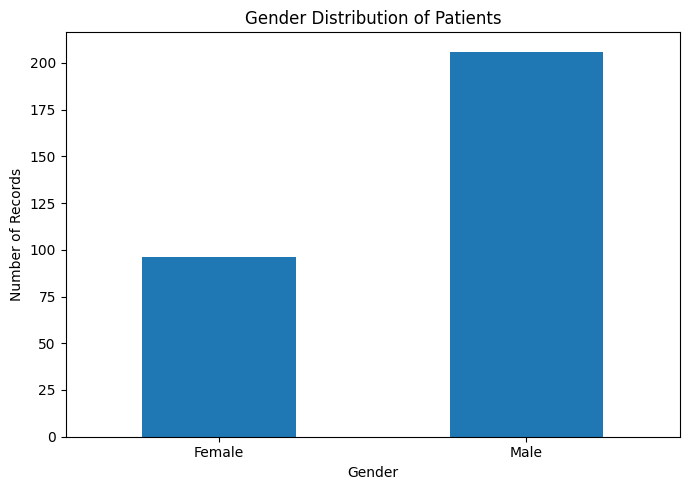

In [22]:
gender_labels = {0: 'Female', 1: 'Male'}

gender_counts.index = gender_counts.index.map(gender_labels)

gender_counts.plot(
    kind='bar',
    figsize=(7, 5),
    title='Gender Distribution of Patients',
    xlabel='Gender',
    ylabel='Number of Records',
    rot=0
)

plt.tight_layout()
plt.show()

In [23]:
#average resting blood pressure of patients
average_bp = df_clean['trestbps'].mean()

print(f"Average resting blood pressure: {average_bp:.2f} mm Hg")

Average resting blood pressure: 131.60 mm Hg


In [24]:
#patients having fasting blood sugar levels higher than 120 mg/dl
high_fbs_count = df_clean['fbs'].sum()

print("Records with fasting blood sugar > 120 mg/dl:", high_fbs_count)

Records with fasting blood sugar > 120 mg/dl: 45


In [25]:
high_fbs_percentage = df_clean['fbs'].mean() * 100

print(f"Percentage of records: {high_fbs_percentage:.2f}%")

Percentage of records: 14.90%


In [26]:
#different types of chest pain recorded
print("Chest pain types:")
print(sorted(df_clean['cp'].unique()))

Chest pain types:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3)]


In [27]:
chest_pain_counts = df_clean['cp'].value_counts().sort_index()

print("Distribution of chest pain types:")
print(chest_pain_counts)

Distribution of chest pain types:
cp
0    143
1     50
2     86
3     23
Name: count, dtype: int64


In [28]:
chest_pain_percentages = (df_clean['cp'].value_counts(normalize=True).sort_index() 
                          * 100)

print("Chest pain distribution (%):")
print(chest_pain_percentages.round(2))

Chest pain distribution (%):
cp
0    47.35
1    16.56
2    28.48
3     7.62
Name: proportion, dtype: float64


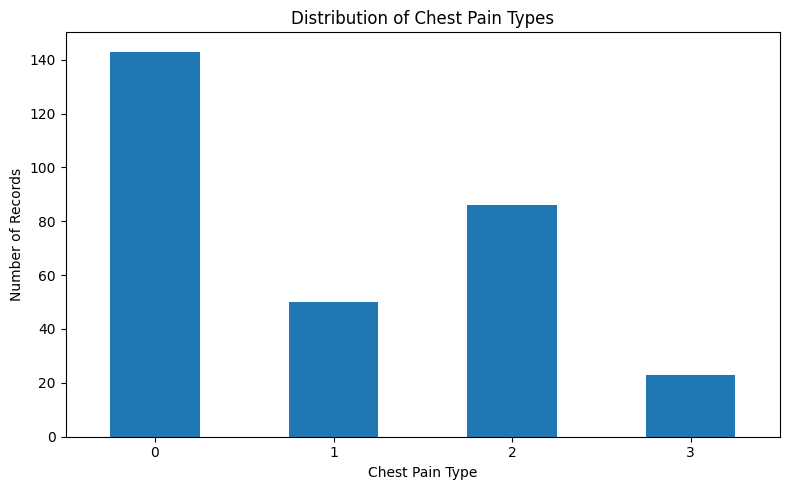

In [29]:
chest_pain_counts.plot(kind='bar',
    figsize=(8, 5),
    title='Distribution of Chest Pain Types',
    xlabel='Chest Pain Type',
    ylabel='Number of Records',
    rot=0)

plt.tight_layout()
plt.show()

In [30]:
#maximum heart rate achieved by patients
max_heart_rate = df_clean['thalach'].max()

print(f"Maximum heart rate achieved: {max_heart_rate} bpm")

Maximum heart rate achieved: 202 bpm


In [31]:
print(f"Average maximum heart rate: {df_clean['thalach'].mean():.2f} bpm")
print(f"Minimum recorded heart rate: {df_clean['thalach'].min()} bpm")

Average maximum heart rate: 149.57 bpm
Minimum recorded heart rate: 71 bpm


In [32]:
#Percentage experiencing exercise-induced angina
angina_count = df_clean['exang'].sum()

print(f"Records with exercise-induced angina: {angina_count}")
print(f"Records without exercise-induced angina: {len(df_clean) - angina_count}")

Records with exercise-induced angina: 99
Records without exercise-induced angina: 203


In [33]:
angina_percentage = df_clean['exang'].mean() * 100

print(f"Percentage experiencing exercise-induced angina: {angina_percentage:.2f}%")

Percentage experiencing exercise-induced angina: 32.78%


In [34]:
#Average Cholesterol Level
average_cholesterol = df_clean['chol'].mean()

print(f"Average cholesterol level: {average_cholesterol:.2f} mg/dl")

Average cholesterol level: 246.50 mg/dl


In [35]:
#patients have a resting electrocardiographic result of 2
ecg_count = (df_clean['restecg'] == 2).sum()

print("Records with resting ECG result of 2:", ecg_count)

Records with resting ECG result of 2: 4


In [36]:
#distribution of the number of major vessels colored by fluoroscopy
ca_counts = df_clean['ca'].value_counts().sort_index()

print("Distribution of major vessels:", ca_counts)

Distribution of major vessels: ca
0    175
1     65
2     38
3     20
4      4
Name: count, dtype: int64


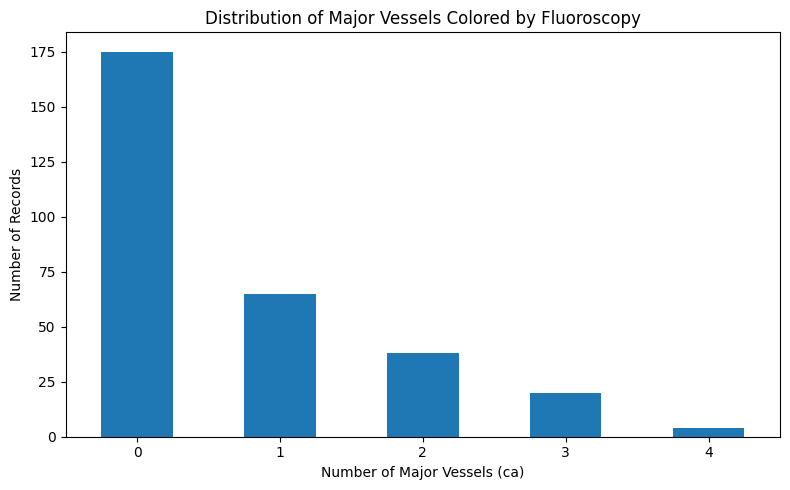

In [37]:
ca_counts.plot(
    kind='bar',
    figsize=(8, 5),
    title='Distribution of Major Vessels Colored by Fluoroscopy',
    xlabel='Number of Major Vessels (ca)',
    ylabel='Number of Records',
    rot=0
)

plt.tight_layout()
plt.show()

In [38]:
ca_percentages = (df_clean['ca'].value_counts(normalize=True).sort_index() * 100)

print("\nDistribution of major vessels (%):")
print(ca_percentages.round(2))


Distribution of major vessels (%):
ca
0    57.95
1    21.52
2    12.58
3     6.62
4     1.32
Name: proportion, dtype: float64


In [39]:
#correlation between age and cholesterol levels
correlation = df_clean[['age', 'chol']].corr().iloc[0, 1]

print(f"Correlation between age and cholesterol: {correlation:.3f}")

Correlation between age and cholesterol: 0.207


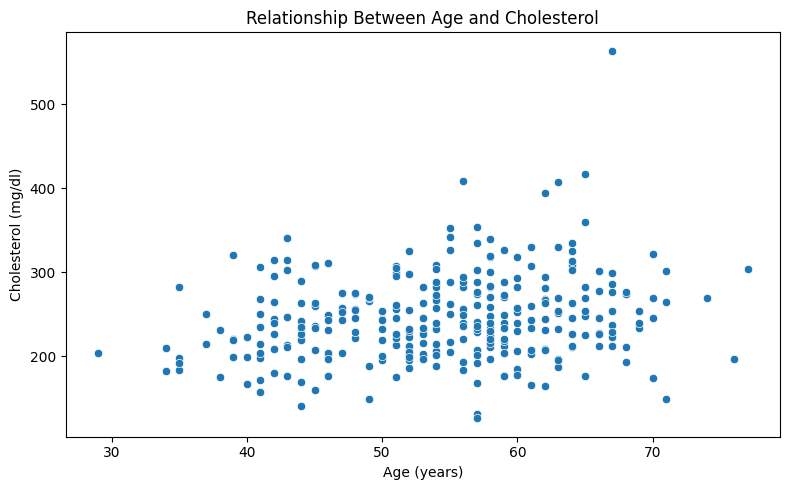

In [40]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df_clean,
    x='age',
    y='chol')

plt.title('Relationship Between Age and Cholesterol')
plt.xlabel('Age (years)')
plt.ylabel('Cholesterol (mg/dl)')

plt.tight_layout()
plt.show()

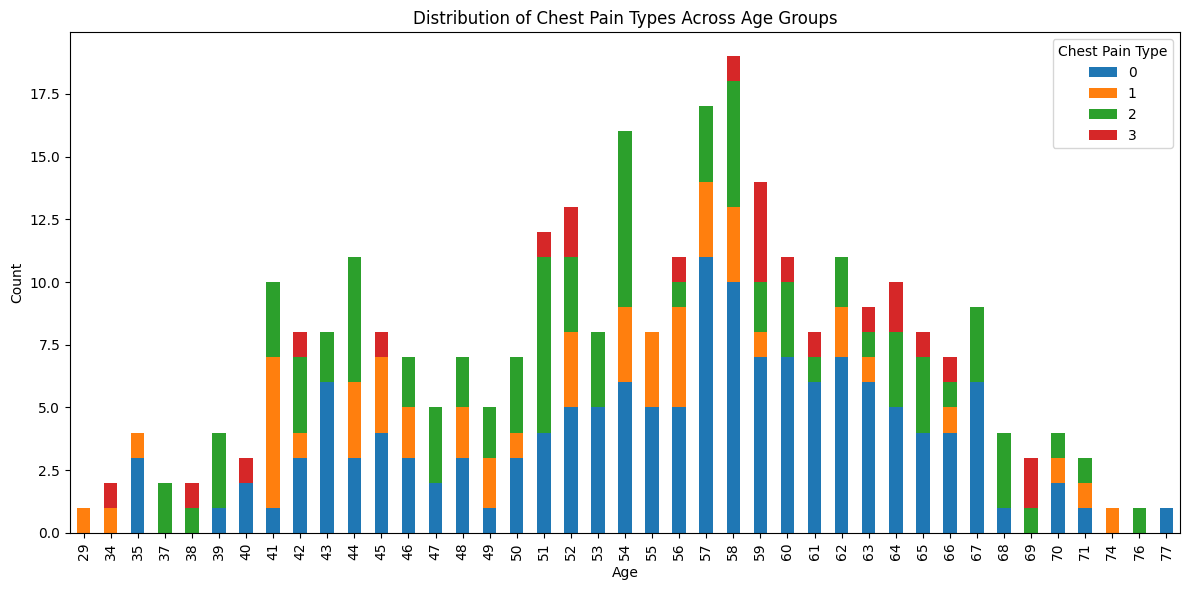

In [41]:
#distribution of chest pain types across different age groups
df_clean.groupby('age')['cp'].value_counts().unstack().plot(kind='bar',stacked=True,figsize=(12, 6))

plt.title('Distribution of Chest Pain Types Across Age Groups')
plt.xlabel('Age')
plt.ylabel('Count')
plt.legend(title='Chest Pain Type')
plt.tight_layout()
plt.show()

In [42]:
#How does maximum heart rate vary with exercise-induced angina? 
heart_rate_by_angina = df_clean.groupby('exang')['thalach'].mean()

print("Average maximum heart rate:")
print(heart_rate_by_angina)

Average maximum heart rate:
exang
0    155.596059
1    137.212121
Name: thalach, dtype: float64


In [43]:
#difference in resting blood pressure between male and female patients
bp_by_sex = df_clean.groupby('sex')['trestbps'].mean()

print("Average resting blood pressure by sex:")
print(bp_by_sex)

Average resting blood pressure by sex:
sex
0    133.083333
1    130.912621
Name: trestbps, dtype: float64


In [44]:
from scipy.stats import ttest_ind

female_bp = df_clean.loc[df_clean['sex'] == 0, 'trestbps']
male_bp = df_clean.loc[df_clean['sex'] == 1, 'trestbps']

t_stat, p_value = ttest_ind(female_bp, male_bp, equal_var=False)

print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {p_value:.4f}")

if p_value < 0.05:
    print("The difference is statistically significant.")
else:
    print("The difference is not statistically significant.")

T-statistic: 0.9485
P-value: 0.3443
The difference is not statistically significant.


In [45]:
#relationship between fasting blood sugar levels and the presence of heart disease
fbs_target = pd.crosstab(df_clean['fbs'], df_clean['target'])

display(fbs_target)

target,0,1
fbs,,
0,116,141
1,22,23


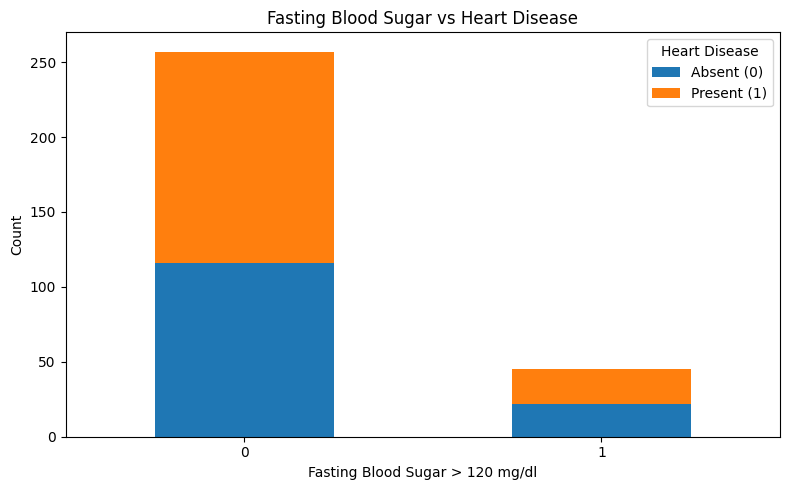

In [46]:
fbs_target.plot(kind='bar', stacked=True, figsize=(8, 5))

plt.title('Fasting Blood Sugar vs Heart Disease')
plt.xlabel('Fasting Blood Sugar > 120 mg/dl')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.legend(title='Heart Disease', labels=['Absent (0)', 'Present (1)'])
plt.tight_layout()
plt.show()

In [47]:
fbs_target_pct = pd.crosstab(df_clean['fbs'],
    df_clean['target'],
    normalize='index') * 100

display(fbs_target_pct.round(2))

target,0,1
fbs,,
0,45.14,54.86
1,48.89,51.11


In [48]:
#How does the number of major vessels (ca) affect the target variable (heart disease presence)?
ca_target = pd.crosstab(df_clean['ca'], df_clean['target'])

display(ca_target)

target,0,1
ca,,
0,45,130
1,44,21
2,31,7
3,17,3
4,1,3


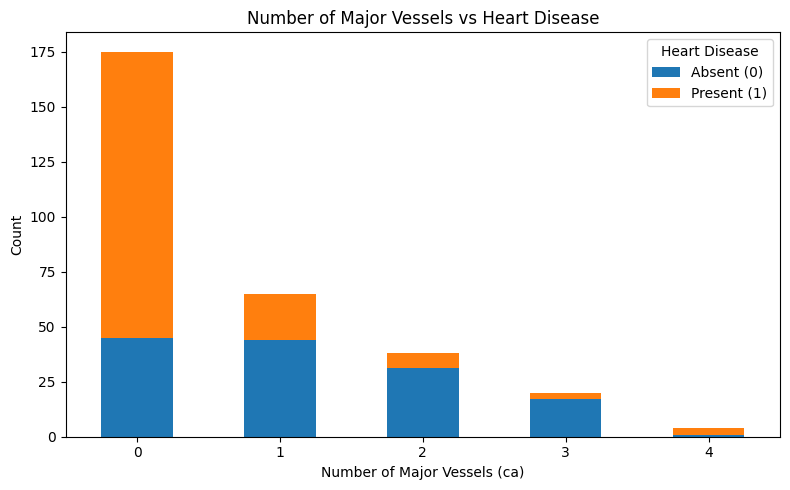

In [49]:
ca_target.plot(kind='bar',
    stacked=True,
    figsize=(8, 5))

plt.title('Number of Major Vessels vs Heart Disease')
plt.xlabel('Number of Major Vessels (ca)')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.legend(title='Heart Disease', labels=['Absent (0)', 'Present (1)'])
plt.tight_layout()
plt.show()

In [50]:
#average oldpeak value for patients with different types of chest pain
df_clean.groupby('cp')['oldpeak'].mean()

cp
0    1.383217
1    0.316000
2    0.806977
3    1.391304
Name: oldpeak, dtype: float64

In [51]:
#distribution of thalassemia types (thal) among patients with heart disease
thal_target = pd.crosstab(df_clean['thal'], df_clean['target'])

display(thal_target)

target,0,1
thal,,
0,1,1
1,12,6
2,36,129
3,89,28


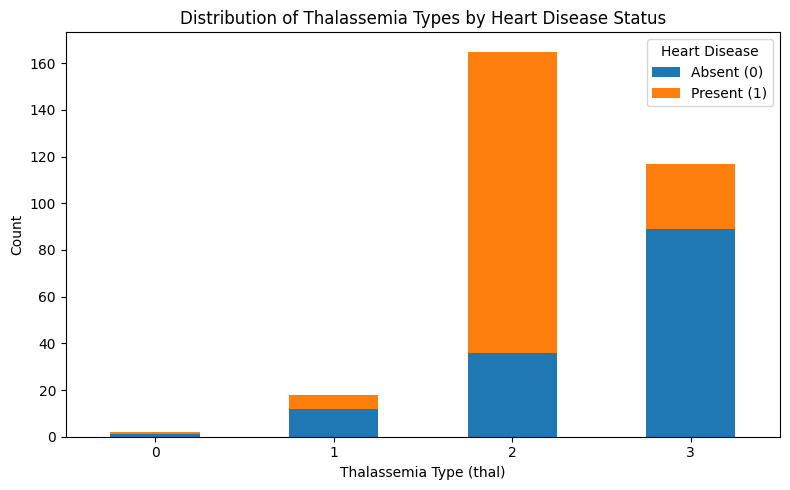

In [52]:
thal_target.plot(kind='bar',
    stacked=True,
    figsize=(8, 5))

plt.title('Distribution of Thalassemia Types by Heart Disease Status')
plt.xlabel('Thalassemia Type (thal)')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.legend(
    title='Heart Disease',
    labels=['Absent (0)', 'Present (1)']
)
plt.tight_layout()
plt.show()

In [53]:
#most common combinations of risk factors in patients with heart disease
common_combinations = (
    df_clean[df_clean['target'] == 1]
    .groupby(['cp', 'fbs', 'exang', 'thal'])
    .size()
    .reset_index(name='counts')
    .sort_values(by='counts', ascending=False))

common_combinations.head(10)

,cp,fbs,exang,thal,counts
15,2,0,0,2,41
8,1,0,0,2,30
1,0,0,0,2,23
19,2,1,0,2,10
4,0,0,1,2,6
16,2,0,0,3,6
23,3,0,0,2,5
9,1,0,0,3,4
17,2,0,1,2,4
20,2,1,0,3,3


In [54]:
#comparison of clinical measurements for patients with and without heart disease
print("Clinical measurements for records with heart disease:")
display(df_clean[df_clean['target'] == 1].describe())

print("Clinical measurements for records without heart disease:")
display(df_clean[df_clean['target'] == 0].describe())

Clinical measurements for records with heart disease:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,164.000000,164.000000,164.000000,164.000000,164.000000,164.000000,164.000000,164.000000,164.000000,164.000000,164.000000,164.000000,164.000000,164.0
mean,52.585366,0.560976,1.371951,129.250000,242.640244,0.140244,0.591463,158.378049,0.140244,0.586585,1.591463,0.341463,2.121951,1.0
std,9.511957,0.497788,0.953878,16.204739,53.456580,0.348303,0.505358,19.199080,0.348303,0.781734,0.594598,0.802137,0.467082,0.0
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,96.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.0
25%,44.750000,0.000000,1.000000,120.000000,208.750000,0.000000,0.000000,148.750000,0.000000,0.000000,1.000000,0.000000,2.000000,1.0
50%,52.000000,1.000000,2.000000,130.000000,234.500000,0.000000,1.000000,161.000000,0.000000,0.200000,2.000000,0.000000,2.000000,1.0
75%,59.000000,1.000000,2.000000,140.000000,267.250000,0.000000,1.000000,172.000000,0.000000,1.025000,2.000000,0.000000,2.000000,1.0
max,76.000000,1.000000,3.000000,180.000000,564.000000,1.000000,2.000000,202.000000,1.000000,4.200000,2.000000,4.000000,3.000000,1.0


Clinical measurements for records without heart disease:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,138.000000,138.000000,138.000000,138.000000,138.000000,138.000000,138.000000,138.000000,138.000000,138.000000,138.000000,138.000000,138.000000,138.0
mean,56.601449,0.826087,0.478261,134.398551,251.086957,0.159420,0.449275,139.101449,0.550725,1.585507,1.166667,1.166667,2.543478,0.0
std,7.962082,0.380416,0.905920,18.729944,49.454614,0.367401,0.541321,22.598782,0.499232,1.300340,0.561324,1.043460,0.684762,0.0
min,35.000000,0.000000,0.000000,100.000000,131.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0
25%,52.000000,1.000000,0.000000,120.000000,217.250000,0.000000,0.000000,125.000000,0.000000,0.600000,1.000000,0.000000,2.000000,0.0
50%,58.000000,1.000000,0.000000,130.000000,249.000000,0.000000,0.000000,142.000000,1.000000,1.400000,1.000000,1.000000,3.000000,0.0
75%,62.000000,1.000000,0.000000,144.750000,283.000000,0.000000,1.000000,156.000000,1.000000,2.500000,1.750000,2.000000,3.000000,0.0
max,77.000000,1.000000,3.000000,200.000000,409.000000,1.000000,2.000000,195.000000,1.000000,6.200000,2.000000,4.000000,3.000000,0.0


In [55]:
# Compare clinical measurements for both groups
comparison = pd.DataFrame({
    'Heart Disease Present (1)': df_clean[df_clean['target'] == 1].mean(numeric_only=True),
    'Heart Disease Absent (0)': df_clean[df_clean['target'] == 0].mean(numeric_only=True)
})

display(comparison.round(2))

,Heart Disease Present (1),Heart Disease Absent (0)
age,52.59,56.60
sex,0.56,0.83
cp,1.37,0.48
trestbps,129.25,134.40
chol,242.64,251.09
fbs,0.14,0.16
restecg,0.59,0.45
thalach,158.38,139.10
exang,0.14,0.55
oldpeak,0.59,1.59


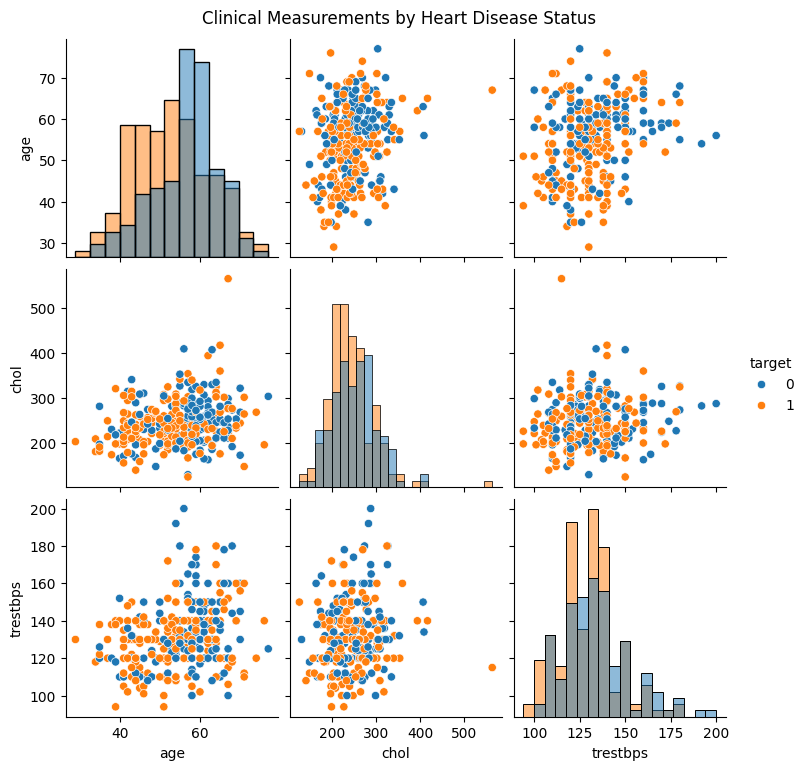

In [56]:
sns.pairplot(
    df_clean,
    hue='target',
    vars=['age', 'chol', 'trestbps'],
    diag_kind='hist')

plt.suptitle(
    'Clinical Measurements by Heart Disease Status',
    y=1.02)

plt.show()

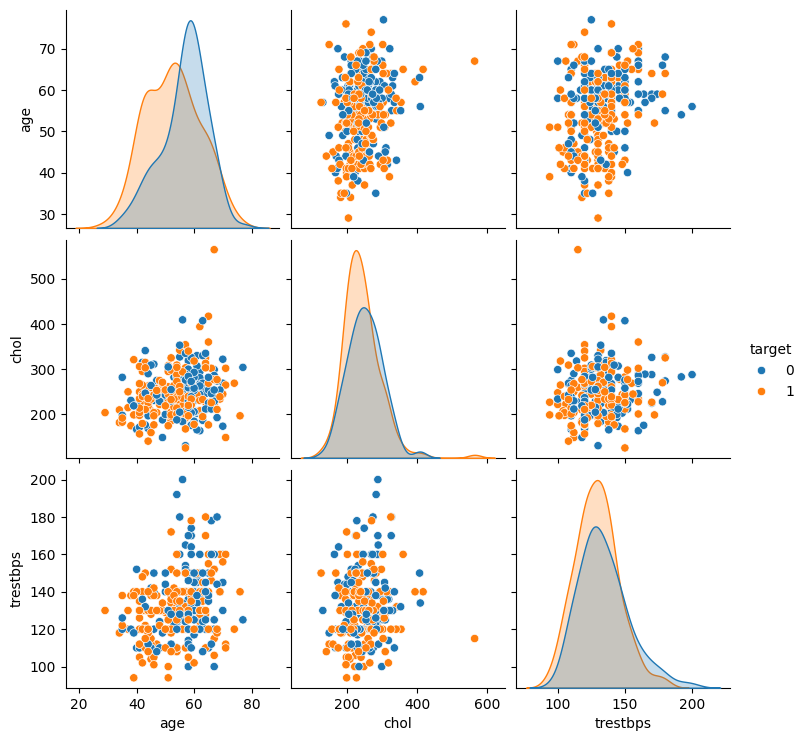

In [57]:
#effect of combining multiple risk factors (age, cholesterol, blood pressure) on the likelihood of heart disease
sns.pairplot(
    df_clean,
    hue='target',
    vars=['age', 'chol', 'trestbps'])

In [58]:
#Which clinical measurement has the strongest correlation with heart disease presence?
target_correlations = (
    df_clean.corr(numeric_only=True)['target']
    .sort_values(ascending=False)
)

display(target_correlations.round(3))

target      1.000
cp          0.432
thalach     0.420
slope       0.344
restecg     0.135
fbs        -0.027
chol       -0.081
trestbps   -0.146
age        -0.221
sex        -0.284
thal       -0.343
ca         -0.409
oldpeak    -0.429
exang      -0.436
Name: target, dtype: float64

In [59]:
#a logistic regression analysis to predict the presence of heart disease using all available features
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

X = df_clean.drop(columns='target')
y = df_clean['target']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y)

In [60]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000))

model.fit(X_train, y_train)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression', LogisticRegression(max_iter=1000))])

In [61]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy:.2%}")

Model Accuracy: 80.33%


In [62]:
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Confusion Matrix:
[[21  7]
 [ 5 28]]

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.75      0.78        28
           1       0.80      0.85      0.82        33

    accuracy                           0.80        61
   macro avg       0.80      0.80      0.80        61
weighted avg       0.80      0.80      0.80        61



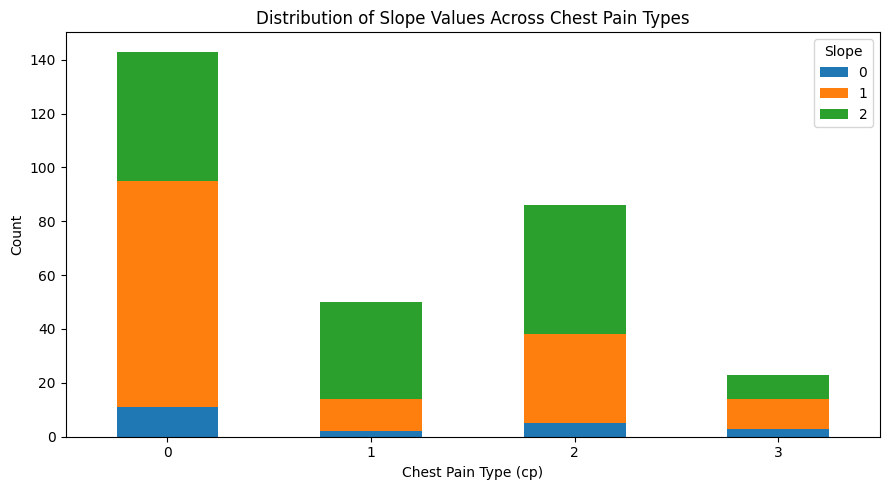

In [63]:
#How do the values of the slope of the peak exercise ST segment (slope) vary with different chest pain types?
df_clean.groupby('cp')['slope'].value_counts().unstack().plot(
    kind='bar',
    stacked=True,
    figsize=(9, 5)
)

plt.title('Distribution of Slope Values Across Chest Pain Types')
plt.xlabel('Chest Pain Type (cp)')
plt.ylabel('Count')
plt.legend(title='Slope')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

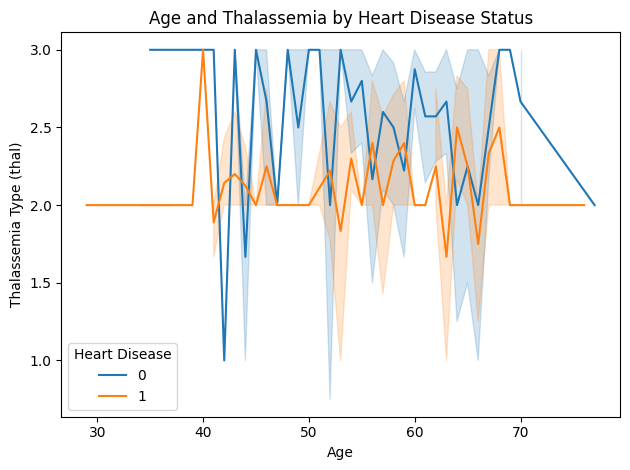

In [64]:
#survival rates of patients with different thalassemia types over a period
sns.lineplot(x='age',
    y='thal',
    hue='target',
    data=df_clean)

plt.title('Age and Thalassemia by Heart Disease Status')
plt.xlabel('Age')
plt.ylabel('Thalassemia Type (thal)')
plt.legend(title='Heart Disease')
plt.tight_layout()
plt.show()